# Домашнее задание № 1

Сбитнева Кристина Витальевна

Курс «Методы машинного обучения». Задание: [hw_1_base.md](https://github.com/AlexandrAxyonov/ml-methods/blob/main/homeworks/hw_1_base.md)

## Шаг 1. Выбор датасета

В работе используется датасет [`scikit-learn/adult-census-income`](https://huggingface.co/datasets/scikit-learn/adult-census-income) с Hugging Face — данные переписи населения США 1994 года. По ним нужно предсказать, зарабатывает ли человек больше 50 тысяч долларов в год, то есть это бинарная классификация с классами `>50K` и `<=50K`. В качестве признаков даны возраст, образование, профессия, семейное положение, число рабочих часов в неделю и так далее.

Датасет выбран не случайно: в нём есть и числовые, и категориальные признаки, встречаются пропуски, а классы несбалансированы. Значит, пригодятся все шаги из задания — импутация, кодирование, масштабирование — и будет хорошо видна разница между accuracy и F1-macro.

In [1]:
%pip install -q datasets scikit-learn pandas matplotlib seaborn

Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datasets import load_dataset

RANDOM_STATE = 42

Matplotlib is building the font cache; this may take a moment.


## Шаг 2. Подготовка

### Загрузка данных

Загружаем датасет через `datasets.load_dataset`. Пропуски здесь записаны строкой `?`, поэтому сразу после загрузки заменим её на `NA` — так pandas и scikit-learn будут видеть их как обычные пропуски.

In [3]:
dataset = load_dataset("scikit-learn/adult-census-income")
df = dataset["train"].to_pandas().replace("?", pd.NA)
df.head()

,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country,income
0,90,NaN,77053,HS-grad,9,Widowed,NaN,Not-in-family,White,Female,0,4356,40,United-States,<=50K
1,82,Private,132870,HS-grad,9,Widowed,Exec-managerial,Not-in-family,White,Female,0,4356,18,United-States,<=50K
2,66,NaN,186061,Some-college,10,Widowed,NaN,Unmarried,Black,Female,0,4356,40,United-States,<=50K
3,54,Private,140359,7th-8th,4,Divorced,Machine-op-inspct,Unmarried,White,Female,0,3900,40,United-States,<=50K
4,41,Private,264663,Some-college,10,Separated,Prof-specialty,Own-child,White,Female,0,3900,40,United-States,<=50K


### EDA: размеры, типы признаков, пропуски

In [4]:
df.shape

(32561, 15)

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   age             32561 non-null  int64
 1   workclass       30725 non-null  str  
 2   fnlwgt          32561 non-null  int64
 3   education       32561 non-null  str  
 4   education.num   32561 non-null  int64
 5   marital.status  32561 non-null  str  
 6   occupation      30718 non-null  str  
 7   relationship    32561 non-null  str  
 8   race            32561 non-null  str  
 9   sex             32561 non-null  str  
 10  capital.gain    32561 non-null  int64
 11  capital.loss    32561 non-null  int64
 12  hours.per.week  32561 non-null  int64
 13  native.country  31978 non-null  str  
 14  income          32561 non-null  str  
dtypes: int64(6), str(9)
memory usage: 6.2 MB


In [6]:
df.isna().sum().sort_values(ascending=False)

occupation        1843
workclass         1836
native.country     583
age                  0
fnlwgt               0
education            0
education.num        0
marital.status       0
relationship         0
race                 0
sex                  0
capital.gain         0
capital.loss         0
hours.per.week       0
income               0
dtype: int64

Пропуски встречаются только в трёх категориальных признаках: `occupation` (около 5,7 %), `workclass` (5,6 %) и `native.country` (1,8 %). Таких строк довольно много, удалять их жалко, поэтому заполним пропуски на этапе предобработки.

### Распределение классов

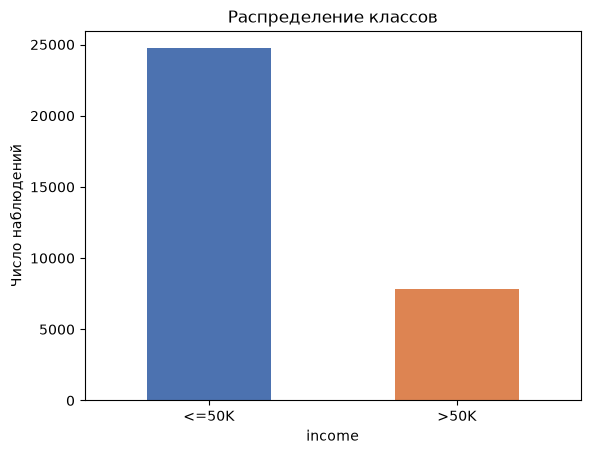

income
<=50K    0.759
>50K     0.241
Name: proportion, dtype: float64

In [7]:
ax = df["income"].value_counts().plot(kind="bar", rot=0, color=["#4c72b0", "#dd8452"])
ax.set_title("Распределение классов")
ax.set_ylabel("Число наблюдений")
plt.show()

df["income"].value_counts(normalize=True).round(3)

Классы несбалансированы: у 76 % людей доход `<=50K` и только у 24 % — `>50K`. Из-за этого accuracy может обманывать: модель, которая всем подряд отвечает `<=50K`, уже получит 0.76. Поэтому основной метрикой в работе будет F1-macro, она одинаково учитывает оба класса.

### Распределения числовых признаков

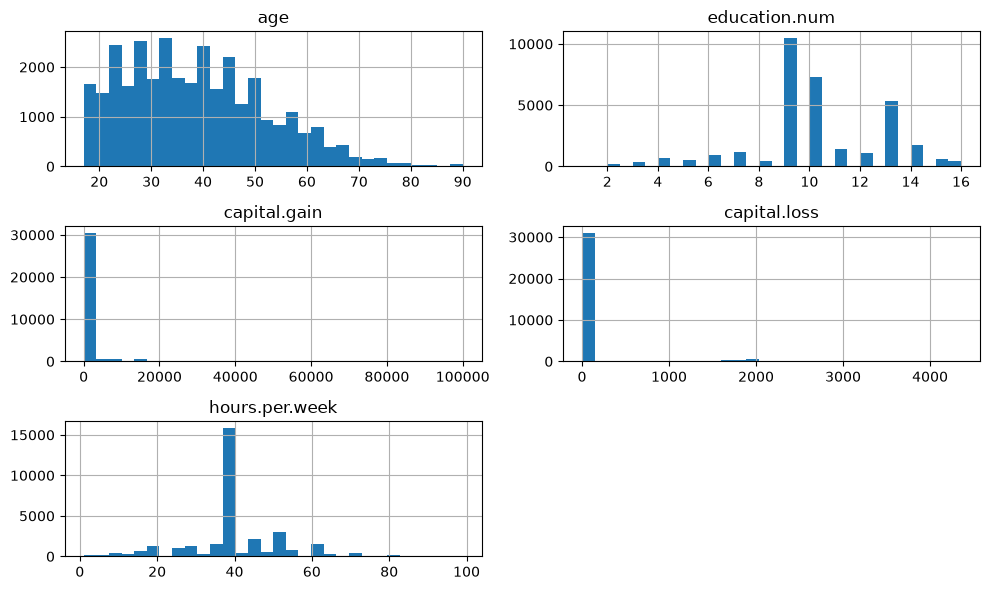

In [8]:
numeric_overview = ["age", "education.num", "capital.gain", "capital.loss", "hours.per.week"]
df[numeric_overview].hist(figsize=(10, 6), bins=30)
plt.tight_layout()
plt.show()

У `capital.gain` и `capital.loss` почти все значения нулевые, а остальные разбросаны далеко вправо. На первый взгляд признаки кажутся почти пустыми, поэтому в шаге 5 проверим, что будет, если один из них убрать.

### Связь признаков с целевой переменной

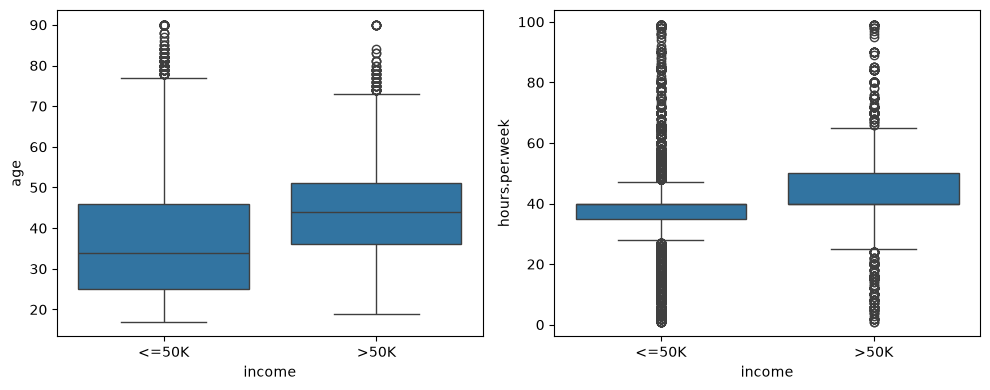

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
sns.boxplot(data=df, x="income", y="age", ax=axes[0])
sns.boxplot(data=df, x="income", y="hours.per.week", ax=axes[1])
plt.tight_layout()
plt.show()

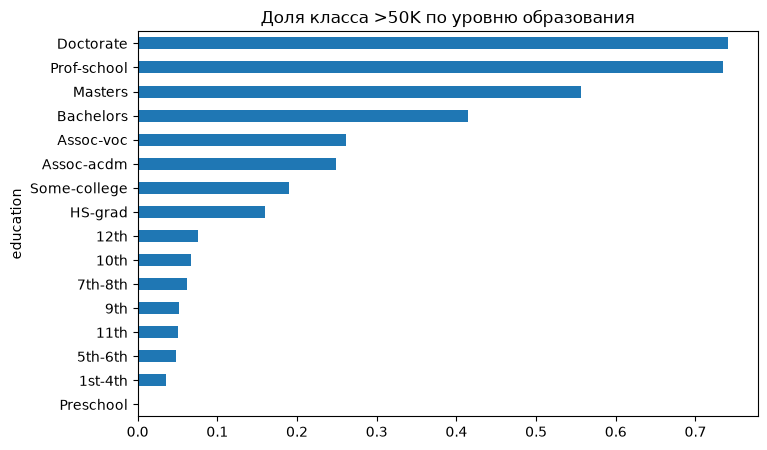

In [10]:
education_share = pd.crosstab(df["education"], df["income"], normalize="index")[">50K"].sort_values()
education_share.plot(kind="barh", figsize=(8, 5), title="Доля класса >50K по уровню образования")
plt.show()

По графикам видно, что люди с доходом `>50K` в среднем старше и работают больше часов в неделю. Доля высокого дохода растёт и с уровнем образования. То есть связь между признаками и целевой переменной есть, моделям будет на что опираться.

### Отбор признаков и разбиение на train/test

Перед обучением уберём два признака. `fnlwgt` — это служебный вес наблюдения в переписи, к доходу конкретного человека он отношения не имеет. А `education` дублирует числовой `education.num`: это одна и та же шкала образования, просто записанная словами, так что оставим только числовой вариант.

In [11]:
from sklearn.model_selection import train_test_split

target_column = "income"
features = df.drop(columns=[target_column, "fnlwgt", "education"])
target = df[target_column]

numeric_features = features.select_dtypes(include="number").columns.tolist()
categorical_features = features.select_dtypes(exclude="number").columns.tolist()
print("Числовые:", numeric_features)
print("Категориальные:", categorical_features)

Числовые: ['age', 'education.num', 'capital.gain', 'capital.loss', 'hours.per.week']
Категориальные: ['workclass', 'marital.status', 'occupation', 'relationship', 'race', 'sex', 'native.country']


In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    features, target, test_size=0.2, stratify=target, random_state=RANDOM_STATE
)
X_train.shape, X_test.shape

((26048, 12), (6513, 12))

### Предобработка: импутация, кодирование, масштабирование

Предобработку собираем в `ColumnTransformer`. Числовые признаки заполняем медианой и стандартизируем, иначе KNN не сможет осмысленно считать расстояния. Категориальные заполняем самым частым значением и кодируем one-hot.

Всё это живёт внутри `Pipeline`, поэтому медианы и частоты считаются только по обучающей выборке, и информация из теста в обучение не утекает.

In [13]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

preprocessor = ColumnTransformer([
    ("num", Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
    ]), numeric_features),
    ("cat", Pipeline([
        ("impute", SimpleImputer(strategy="most_frequent")),
        ("encode", OneHotEncoder(handle_unknown="ignore")),
    ]), categorical_features),
])

## Шаг 3. Модели

### Logistic Regression

In [14]:
from sklearn.linear_model import LogisticRegression

log_reg = Pipeline([
    ("prep", preprocessor),
    ("model", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
])
log_reg.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](2,)","['<=50K','>50K']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](12,)","['age','workclass','education.num',...,'capital.loss','hours.per.week', 'native.country']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,12
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder

### KNN

In [15]:
from sklearn.neighbors import KNeighborsClassifier

knn = Pipeline([
    ("prep", preprocessor),
    ("model", KNeighborsClassifier(n_neighbors=15)),
])
knn.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](2,)","['<=50K','>50K']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](12,)","['age','workclass','education.num',...,'capital.loss','hours.per.week', 'native.country']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,12
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder

## Шаг 4. Оценка качества

### Accuracy и F1-macro

In [16]:
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay

models = {"Logistic Regression": log_reg, "KNN (k=15)": knn}
predictions = {name: model.predict(X_test) for name, model in models.items()}

results = pd.DataFrame({
    name: {
        "accuracy": accuracy_score(y_test, pred),
        "f1_macro": f1_score(y_test, pred, average="macro"),
    }
    for name, pred in predictions.items()
}).T.round(3)
results

,accuracy,f1_macro
Logistic Regression,0.852,0.784
KNN (k=15),0.849,0.784


### Confusion matrix

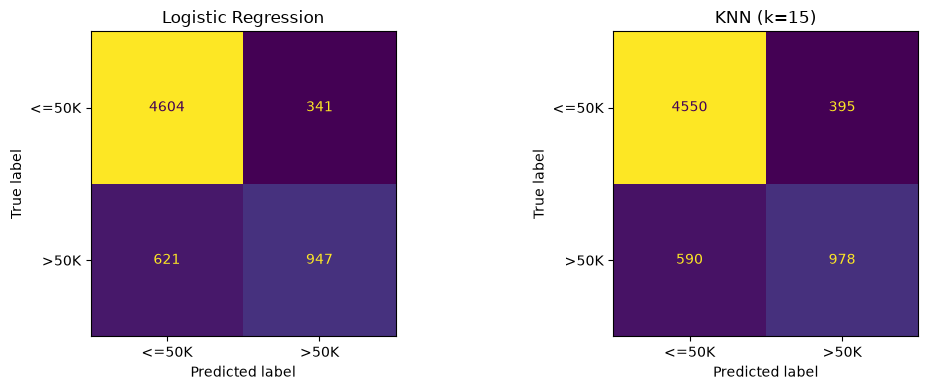

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (name, pred) in zip(axes, predictions.items()):
    ConfusionMatrixDisplay.from_predictions(y_test, pred, ax=ax, colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.show()

### Classification report

In [18]:
for name, pred in predictions.items():
    print(name)
    print(classification_report(y_test, pred))

Logistic Regression
              precision    recall  f1-score   support

       <=50K       0.88      0.93      0.91      4945
        >50K       0.74      0.60      0.66      1568

    accuracy                           0.85      6513
   macro avg       0.81      0.77      0.78      6513
weighted avg       0.85      0.85      0.85      6513

KNN (k=15)
              precision    recall  f1-score   support

       <=50K       0.89      0.92      0.90      4945
        >50K       0.71      0.62      0.67      1568

    accuracy                           0.85      6513
   macro avg       0.80      0.77      0.78      6513
weighted avg       0.84      0.85      0.85      6513



По общим метрикам модели почти не различаются: у обеих accuracy около 0.85 и F1-macro около 0.78. Интереснее посмотреть на классы по отдельности.

Класс `<=50K` предсказывается хорошо: его F1 около 0.90, recall 0.92–0.93. С классом `>50K` всё заметно хуже: F1 только 0.66–0.67, recall около 0.60. Получается, что примерно 40 % людей с высоким доходом модель пропускает и относит к `<=50K`. На confusion matrix это и есть основная масса ошибок.

Причина в дисбалансе: класса `<=50K` в три раза больше, и модели выгоднее ошибаться в его сторону. По той же причине accuracy (0.85) выглядит лучше, чем F1-macro (0.78).

## Шаг 5. Эксперименты

### Подбор `k` для KNN

In [19]:
k_values = [3, 5, 11, 21, 41]
rows = []
for k in k_values:
    model = Pipeline([
        ("prep", preprocessor),
        ("model", KNeighborsClassifier(n_neighbors=k)),
    ])
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    rows.append({
        "k": k,
        "accuracy": accuracy_score(y_test, pred),
        "f1_macro": f1_score(y_test, pred, average="macro"),
    })
k_results = pd.DataFrame(rows).set_index("k").round(3)
k_results

,accuracy,f1_macro
k,,
3,0.827,0.755
5,0.838,0.770
11,0.845,0.778
21,0.847,0.781
41,0.850,0.784


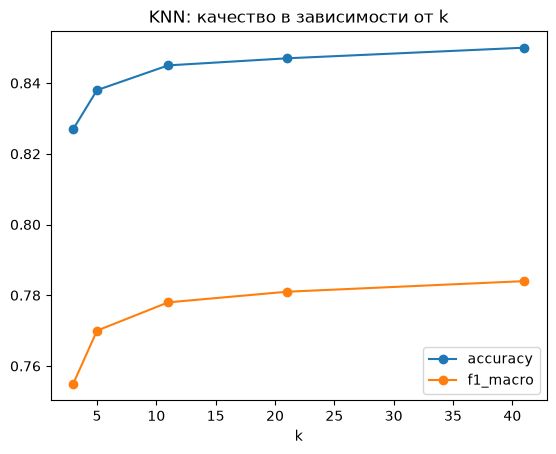

In [20]:
k_results.plot(marker="o", title="KNN: качество в зависимости от k")
plt.show()

### Сила регуляризации `C` для логистической регрессии

In [21]:
c_values = [0.01, 0.1, 1, 10]
rows = []
for c in c_values:
    model = Pipeline([
        ("prep", preprocessor),
        ("model", LogisticRegression(C=c, max_iter=1000, random_state=RANDOM_STATE)),
    ])
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    rows.append({
        "C": c,
        "accuracy": accuracy_score(y_test, pred),
        "f1_macro": f1_score(y_test, pred, average="macro"),
    })
pd.DataFrame(rows).set_index("C").round(3)

,accuracy,f1_macro
C,,
0.01,0.852,0.779
0.10,0.852,0.783
1.00,0.852,0.784
10.00,0.852,0.784


У KNN качество стабильно растёт с увеличением `k`: F1-macro поднимается с 0.755 при `k=3` до 0.784 при `k=41`. При маленьком `k` ответ зависит от нескольких ближайших точек, среди которых много шума, поэтому модель переобучается. С большим `k` ответ усредняется по многим соседям и становится устойчивее. Догнать логистическую регрессию KNN удаётся только при больших `k`.

Логистическая регрессия на изменение `C` почти не реагирует: accuracy 0.852 при любом значении, F1-macro меняется в третьем знаке. Обучающих данных много (26 тысяч строк), а признаков относительно мало, поэтому регуляризация здесь мало что решает.

### Удаление признака `capital.gain`

In [22]:
dropped = "capital.gain"
numeric_reduced = [c for c in numeric_features if c != dropped]

preprocessor_reduced = ColumnTransformer([
    ("num", Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
    ]), numeric_reduced),
    ("cat", Pipeline([
        ("impute", SimpleImputer(strategy="most_frequent")),
        ("encode", OneHotEncoder(handle_unknown="ignore")),
    ]), categorical_features),
])

log_reg_reduced = Pipeline([
    ("prep", preprocessor_reduced),
    ("model", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
])
log_reg_reduced.fit(X_train.drop(columns=[dropped]), y_train)
pred_reduced = log_reg_reduced.predict(X_test.drop(columns=[dropped]))

pd.DataFrame({
    "со всеми признаками": results.loc["Logistic Regression"],
    f"без {dropped}": {
        "accuracy": accuracy_score(y_test, pred_reduced),
        "f1_macro": f1_score(y_test, pred_reduced, average="macro"),
    },
}).round(3)

,со всеми признаками,без capital.gain
accuracy,0.852,0.836
f1_macro,0.784,0.759


Удаление одного только `capital.gain` заметно портит модель: accuracy падает с 0.852 до 0.836, а F1-macro — с 0.784 до 0.759. Это сходится с тем, что мы видели в EDA: доход с капитала почти у всех нулевой, но если он есть, то это сильный сигнал высокого дохода. Ниже это подтвердится и коэффициентами регрессии.

### Кросс-валидация (бонус)

Проверим, насколько устойчивы результаты: сделаем кросс-валидацию на 5 фолдов по обучающей выборке с метрикой F1-macro.

In [23]:
from sklearn.model_selection import cross_val_score

cv_scores = pd.DataFrame({
    name: cross_val_score(model, X_train, y_train, cv=5, scoring="f1_macro")
    for name, model in models.items()
})
cv_scores.round(3)

,Logistic Regression,KNN (k=15)
0,0.780,0.786
1,0.772,0.776
2,0.784,0.779
3,0.776,0.782
4,0.790,0.777


In [24]:
cv_scores.agg(["mean", "std"]).round(3)

,Logistic Regression,KNN (k=15)
mean,0.781,0.780
std,0.007,0.004


По пяти фолдам логистическая регрессия даёт F1-macro 0.781 ± 0.007, KNN — 0.780 ± 0.004. Эти оценки близки к результату на отложенном тесте (0.784), значит, с разбиением нам не просто повезло. Разница между моделями меньше разброса по фолдам, так что по качеству они фактически одинаковы.

### Важность признаков по коэффициентам логистической регрессии

In [25]:
feature_names = log_reg["prep"].get_feature_names_out()
coefficients = pd.Series(log_reg["model"].coef_[0], index=feature_names)
coefficients.reindex(coefficients.abs().sort_values(ascending=False).index).head(10).round(2)

num__capital.gain                         2.29
cat__occupation_Priv-house-serv          -1.42
cat__marital.status_Married-AF-spouse     1.38
cat__native.country_Cambodia              1.36
cat__relationship_Own-child              -1.30
cat__marital.status_Married-civ-spouse    1.27
cat__marital.status_Never-married        -1.10
cat__relationship_Wife                    1.06
cat__native.country_Greece               -1.05
cat__occupation_Farming-fishing          -1.02
dtype: float64

## Шаг 6. Итог

Обе модели показали одинаковое качество: F1-macro 0.784 на тесте и около 0.78 на кросс-валидации. Раз по метрикам разницы нет, выбирать стоит логистическую регрессию: она обучается и предсказывает намного быстрее, не требует хранить всю выборку, а по её коэффициентам можно понять, на что модель опирается.

Самым важным признаком оказался `capital.gain`: без него F1-macro падает на 0.025, и у него самый большой по модулю коэффициент регрессии. Сильно влияет и семейное положение: статус `Married-civ-spouse` повышает шанс класса `>50K`, а `Never-married` и `Own-child`, наоборот, понижают. Образование и число рабочих часов тоже вносят заметный вклад.

Ошибаются обе модели чаще всего одинаково: пропускают класс `>50K`, то есть принимают человека с высоким доходом за человека с низким. Так происходит примерно с 40 % богатых из теста, и причина всё в том же дисбалансе классов. Логичное продолжение работы — попробовать `class_weight="balanced"` или сдвинуть порог классификации.

Кросс-валидация из бонусного пункта сделана в шаге 5. Она показала, что разброс качества по фолдам совсем небольшой (±0.007), поэтому выводам выше можно доверять.